# Random-exit thinking-leakage and oracle analysis

This notebook is a separate, executable analysis for the controlled random-exit continuations described in `thinking_leakage_analysis_plan.md`. It evaluates correctness first, reconstructs the deterministic exit plan, checks eight-rollout completeness, and then runs the analyses supported by the current data.

**Claims.** Vulnerability curves are descriptive associations over controlled exit positions. Stable frontiers are hindsight oracle bounds over sampled positions, not deployable stopping rules. The structural `</think>` marker is the primary leakage label; ordinary words such as *wait* and *actually* are reported only as a sensitivity diagnostic. Multiple rollouts and positions from one `data_id` are dependent, so confidence intervals resample trajectories.

## 1. Paths and evaluation step

Set `RUN_EVALUATION=False` to reuse an existing evaluated snapshot. Evaluation is atomic and adds only top-level `correct` to each flat continuation row.

In [12]:
from pathlib import Path
import subprocess
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / 'random_exit').is_dir():
    candidates = [ROOT, *ROOT.parents]
    ROOT = next(path for path in candidates if (path / 'random_exit').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

RAW = ROOT / 'output/random_exit/math500.qwen35_4b.jsonl'
EVALUATED = ROOT / 'output/random_exit/math500.qwen35_4b.evaluated.jsonl'
PREPARED = ROOT / 'data/random_exit/math500/math500.qwen35_4b.jsonl'
METADATA = ROOT / 'output/random_exit/math500.qwen35_4b.metadata.json'
TABLE_DIR = ROOT / 'output/random_exit/analysis/math500.qwen35_4b'
RUN_EVALUATION = True

for path in (RAW, PREPARED, METADATA):
    if not path.exists():
        raise FileNotFoundError(path)

if RUN_EVALUATION:
    subprocess.run([
        sys.executable, str(ROOT / 'scripts/rerun_random_exit_eval.py'), str(RAW),
        '--prepared-input', str(PREPARED), '--config', str(ROOT / 'scripts/config.yml'),
        '--evaluator', 'math500', '--output', str(EVALUATED),
    ], check=True)
elif not EVALUATED.exists():
    raise FileNotFoundError(f'Evaluated snapshot does not exist: {EVALUATED}')

print(f'Notebook input: {EVALUATED}')

Wrote 11,800 rows to /home/quanghung20gg/Documents/new/early-exit/output/random_exit/math500.qwen35_4b.evaluated.jsonl (evaluated=11,800, preserved=0, correct=9,468, incorrect=2,332, failed_generation=0)
Notebook input: /home/quanghung20gg/Documents/new/early-exit/output/random_exit/math500.qwen35_4b.evaluated.jsonl


## 2. Load, reconstruct, and validate

The model tokenizer reconstructs exact full reasoning lengths from each prepared trajectory. The same deterministic position planner used during generation reconstructs all expected `(data_id, position, num_run)` keys. Unexpected or duplicate keys fail fast. Partial positions are excluded from rate estimates, and incomplete trajectories are excluded from stable-frontier inference.

In [13]:
!pip install dotenv

In [14]:
from IPython.display import display
import pandas as pd

from random_exit.analysis import (
    answer_onset, load_bundle, plot_answer_onset, plot_frontier,
    plot_raster, plot_vulnerability, stable_frontiers, summary_tables,
)

bundle = load_bundle(EVALUATED, PREPARED, metadata_path=METADATA)
tables = summary_tables(bundle)
display(tables['headline'].style.format({
    'accuracy': '{:.2%}', 'primary_leakage_rate': '{:.3%}',
    'soft_marker_rate': '{:.2%}', 'safe_primary_rate': '{:.2%}',
    'truncated_rate': '{:.2%}',
}))

,observed_rows,expected_rows,missing_rows,observed_trajectories,complete_trajectories,complete_positions,accuracy,primary_leakage_rate,soft_marker_rate,safe_primary_rate,truncated_rate
0,11800,30864,19064,25,24,1475,80.24%,0.076%,5.86%,80.17%,16.29%


In [15]:
completion = tables['completeness'].copy()
display(completion)
complete_n = int(completion['trajectory_complete'].sum())
print(f'Complete trajectories eligible for oracle frontiers: {complete_n}/{len(completion)}')
if complete_n < len(completion):
    print('CAUTION: generation is still partial; pooled estimates describe this snapshot only.')

,trajectory_id,data_id,dataset,model_prepared,planned_positions,expected_continuations,observed_continuations,missing_continuations,trajectory_complete
0,math500::qwen35_4b::math500:8,math500:8,math500,qwen35_4b,64,512,512,0,True
1,math500::qwen35_4b::math500:22,math500:22,math500,qwen35_4b,64,512,512,0,True
2,math500::qwen35_4b::math500:33,math500:33,math500,qwen35_4b,64,512,512,0,True
3,math500::qwen35_4b::math500:39,math500:39,math500,qwen35_4b,37,296,296,0,True
4,math500::qwen35_4b::math500:50,math500:50,math500,qwen35_4b,34,272,272,0,True
...,...,...,...,...,...,...,...,...,...
59,math500::qwen35_4b::math500:488,math500:488,math500,qwen35_4b,64,512,0,512,False
60,math500::qwen35_4b::math500:489,math500:489,math500,qwen35_4b,64,512,0,512,False
61,math500::qwen35_4b::math500:492,math500:492,math500,qwen35_4b,64,512,0,512,False
62,math500::qwen35_4b::math500:493,math500:493,math500,qwen35_4b,64,512,0,512,False


Complete trajectories eligible for oracle frontiers: 24/64
CAUTION: generation is still partial; pooled estimates describe this snapshot only.


## 3. Outcome definitions and pooled support

A rollout is primary-safe iff generation succeeded, the Math500 evaluator marks it correct, and its output does not contain `</think>`. `soft_marker` detects whole-word *wait* or *actually* only as sensitivity evidence; it is not treated as validated leakage in the headline result. A position is complete only when all configured independent runs are present.

In [16]:
position_summary = tables['positions'][[
    'data_id', 'position', 'position_ratio', 'observed_runs', 'correct_rate',
    'primary_leakage_rate', 'combined_leakage_rate', 'safe_primary_rate',
    'truncated_rate',
]].sort_values(['data_id', 'position'])
display(position_summary.head(20).style.format({
    'position_ratio': '{:.1%}', 'correct_rate': '{:.1%}',
    'primary_leakage_rate': '{:.2%}', 'combined_leakage_rate': '{:.1%}',
    'safe_primary_rate': '{:.1%}', 'truncated_rate': '{:.1%}',
}))

,data_id,position,position_ratio,observed_runs,correct_rate,primary_leakage_rate,combined_leakage_rate,safe_primary_rate,truncated_rate
0,math500:109,666,2.8%,8,0.0%,0.00%,75.0%,0.0%,100.0%
1,math500:109,1018,4.2%,8,0.0%,0.00%,75.0%,0.0%,100.0%
2,math500:109,1114,4.6%,8,0.0%,0.00%,62.5%,0.0%,100.0%
3,math500:109,1242,5.1%,8,0.0%,0.00%,25.0%,0.0%,100.0%
4,math500:109,1562,6.5%,8,0.0%,0.00%,0.0%,0.0%,100.0%
5,math500:109,3194,13.2%,8,0.0%,0.00%,0.0%,0.0%,100.0%
6,math500:109,3386,14.0%,8,0.0%,0.00%,0.0%,0.0%,100.0%
7,math500:109,3546,14.7%,8,0.0%,0.00%,0.0%,0.0%,100.0%
8,math500:109,4474,18.5%,8,0.0%,0.00%,12.5%,0.0%,100.0%
9,math500:109,5530,22.9%,8,0.0%,0.00%,12.5%,0.0%,100.0%


In [17]:
complete_position_keys = tables['positions'][['data_id', 'position']]
analysis_rows = bundle.rows.merge(
    complete_position_keys, on=['data_id', 'position'], how='inner', validate='many_to_one'
)
strata = []
for level, column in [('pooled', None), ('dataset', 'dataset'), ('model', 'model')]:
    groups = [('All', analysis_rows)] if column is None else analysis_rows.groupby(column, dropna=False)
    for name, group in groups:
        strata.append({
            'level': level, 'group': name, 'rollouts': len(group),
            'trajectories': group['data_id'].nunique(),
            'accuracy': group['correct'].mean(),
            'primary_leakage_rate': group['primary_leakage'].mean(),
            'safe_primary_rate': group['safe_primary'].mean(),
            'truncated_rate': group['answer_truncated'].mean(),
        })
stratified_summary = pd.DataFrame(strata)
display(stratified_summary.style.format({
    'accuracy': '{:.2%}', 'primary_leakage_rate': '{:.3%}',
    'safe_primary_rate': '{:.2%}', 'truncated_rate': '{:.2%}',
}))

,level,group,rollouts,trajectories,accuracy,primary_leakage_rate,safe_primary_rate,truncated_rate
0,pooled,All,11800,25,80.24%,0.076%,80.17%,16.29%
1,dataset,math500,11800,25,80.24%,0.076%,80.17%,16.29%
2,model,qwen35_4b,11800,25,80.24%,0.076%,80.17%,16.29%


## 4. Analysis I — normalized-position vulnerability

The table estimates structural-marker leakage in ten normalized reasoning-progress bins. Confidence intervals use a trajectory-cluster percentile bootstrap. Relative risk is intentionally left undefined when the 90–100% reference risk is zero; risk difference remains interpretable.

,level,group,ratio_bin,exits,trajectories,leakage_rate,ci_low,ci_high,bin_left,bin_right,bin_center,reference_rate_90_100,relative_risk,risk_difference
0,pooled,All,0,1168,25,0.000%,0.000%,0.000%,0%,10%,0.050000,0.000%,nan,0.000%
1,pooled,All,1,1240,25,0.081%,0.000%,0.259%,10%,20%,0.150000,0.000%,nan,0.081%
2,pooled,All,2,1160,25,0.431%,0.000%,1.153%,20%,30%,0.250000,0.000%,nan,0.431%
3,pooled,All,3,1200,25,0.167%,0.000%,0.517%,30%,40%,0.350000,0.000%,nan,0.167%
4,pooled,All,4,1152,24,0.087%,0.000%,0.270%,40%,50%,0.450000,0.000%,nan,0.087%
5,pooled,All,5,1208,24,0.000%,0.000%,0.000%,50%,60%,0.550000,0.000%,nan,0.000%
6,pooled,All,6,1160,24,0.000%,0.000%,0.000%,60%,70%,0.650000,0.000%,nan,0.000%
7,pooled,All,7,1280,24,0.000%,0.000%,0.000%,70%,80%,0.750000,0.000%,nan,0.000%
8,pooled,All,8,1072,24,0.000%,0.000%,0.000%,80%,90%,0.850000,0.000%,nan,0.000%
9,pooled,All,9,1160,24,0.000%,0.000%,0.000%,90%,100%,0.950000,0.000%,nan,0.000%


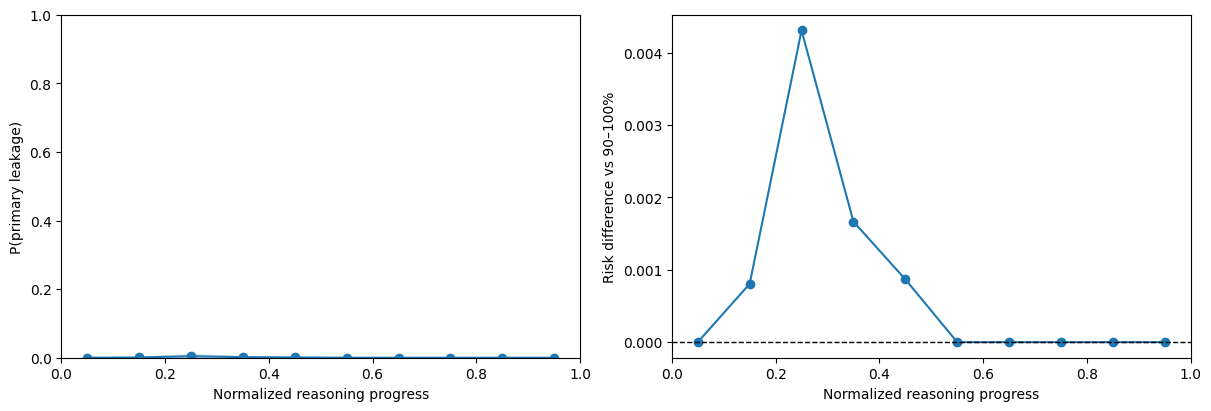

In [18]:
vulnerability = tables['vulnerability']
display(vulnerability.style.format({
    'bin_left': '{:.0%}', 'bin_right': '{:.0%}', 'leakage_rate': '{:.3%}',
    'ci_low': '{:.3%}', 'ci_high': '{:.3%}',
    'reference_rate_90_100': '{:.3%}', 'relative_risk': '{:.2f}',
    'risk_difference': '{:.3%}',
}))
try:
    import matplotlib.pyplot as plt
    plot_vulnerability(vulnerability)
    plt.show()
    PLOTS_AVAILABLE = True
except ImportError:
    PLOTS_AVAILABLE = False
    print('Install matplotlib in this kernel to render figures; all tables remain available.')

## 5. Analyses II–III — stable oracle frontier and survival view

Eight stochastic continuations turn safety into a rate at each position. The strict primary result requires 100% of rollouts at a position to be correct and structurally clean; 50% and 75% thresholds are reported as sensitivity analyses. A stable frontier is the earliest sampled position meeting the threshold at every later sampled position. No observed stable frontier is right-censored at the final sampled position.

,safe_rate_threshold,trajectories,observed,median_tokens,median_ratio,observed_fraction
0,50%,24,22,155,2.3%,91.7%
1,75%,24,22,739,16.4%,91.7%
2,100%,24,16,4660,73.8%,66.7%


,trajectory_id,data_id,dataset,model,frontier_observed,frontier_tokens,frontier_ratio,sequence_type,safe_rate_threshold
0,math500::qwen35_4b::math500:109,math500:109,math500,qwen35_4b,True,20666.0,0.854426,non-monotonic,0.5
1,math500::qwen35_4b::math500:116,math500:116,math500,qwen35_4b,True,1441.0,0.314698,non-monotonic,0.5
2,math500::qwen35_4b::math500:138,math500:138,math500,qwen35_4b,True,155.0,0.023252,monotonic unsafe to safe,0.5
3,math500::qwen35_4b::math500:142,math500:142,math500,qwen35_4b,True,200.0,0.022800,monotonic unsafe to safe,0.5
4,math500::qwen35_4b::math500:143,math500:143,math500,qwen35_4b,True,88.0,0.018864,always safe,0.5
5,math500::qwen35_4b::math500:154,math500:154,math500,qwen35_4b,True,8707.0,0.546888,non-monotonic,0.5
6,math500::qwen35_4b::math500:166,math500:166,math500,qwen35_4b,True,55.0,0.020960,always safe,0.5
7,math500::qwen35_4b::math500:170,math500:170,math500,qwen35_4b,True,16.0,0.011453,always safe,0.5
8,math500::qwen35_4b::math500:173,math500:173,math500,qwen35_4b,True,3.0,0.001589,always safe,0.5
9,math500::qwen35_4b::math500:181,math500:181,math500,qwen35_4b,True,28.0,0.008081,always safe,0.5


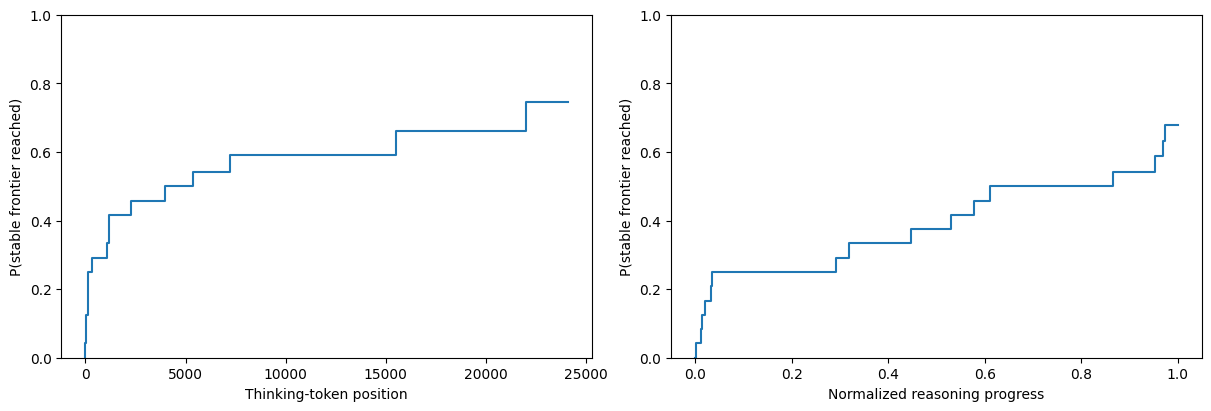

In [19]:
frontiers = tables['frontiers']
frontier_summary = (
    frontiers.groupby('safe_rate_threshold', as_index=False)
    .agg(trajectories=('data_id', 'size'), observed=('frontier_observed', 'sum'),
         median_tokens=('frontier_tokens', 'median'), median_ratio=('frontier_ratio', 'median'))
)
frontier_summary['observed_fraction'] = frontier_summary['observed'] / frontier_summary['trajectories']
display(frontier_summary.style.format({
    'safe_rate_threshold': '{:.0%}', 'observed_fraction': '{:.1%}',
    'median_tokens': '{:.0f}', 'median_ratio': '{:.1%}',
}))
display(frontiers.head(20))
if PLOTS_AVAILABLE and len(frontiers):
    plot_frontier(frontiers, threshold=1.0)
    plt.show()

## 6. Analysis V — trajectory raster

Each point is one complete sampled position and color is the fraction of its eight rollouts that are primary-safe. Black ticks mark strict stable frontiers. Only fully generated trajectories contribute.

,sequence_type,trajectories
0,always safe,4
1,monotonic unsafe to safe,2
2,never safe,2
3,non-monotonic,16


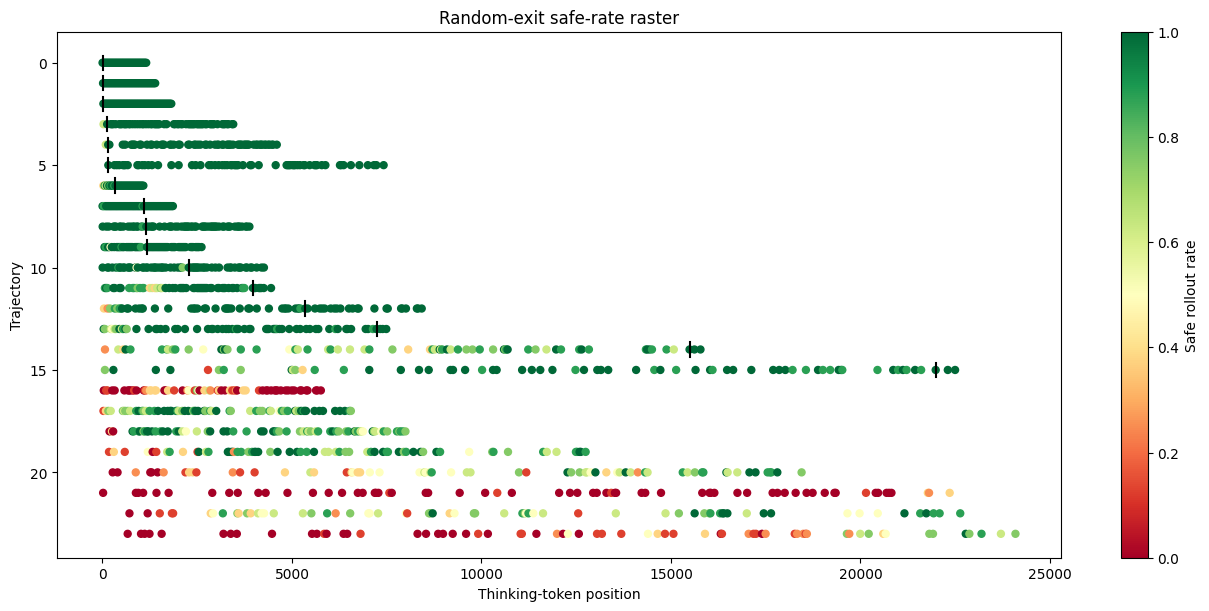

In [20]:
sequence_summary = (
    frontiers[frontiers['safe_rate_threshold'].eq(1.0)]
    .groupby('sequence_type').size().rename('trajectories').reset_index()
)
display(sequence_summary)
if PLOTS_AVAILABLE and len(frontiers):
    plot_raster(bundle, threshold=1.0, limit=60)
    plt.show()

## 7. Analysis VI — structural leakage onset in the answer

The event is the first `</think>` marker. Non-leaking outputs are right-censored at observed whitespace length. Length-finished answers remain censored observations; absence of a marker beyond the generation cap is not asserted.

,answers,events,event_rate,right_censored,cap_truncated_without_event,median_onset_token_if_event,median_onset_ratio_if_event
0,11800,9,0.076%,11791,1917,216.000000,61.9%


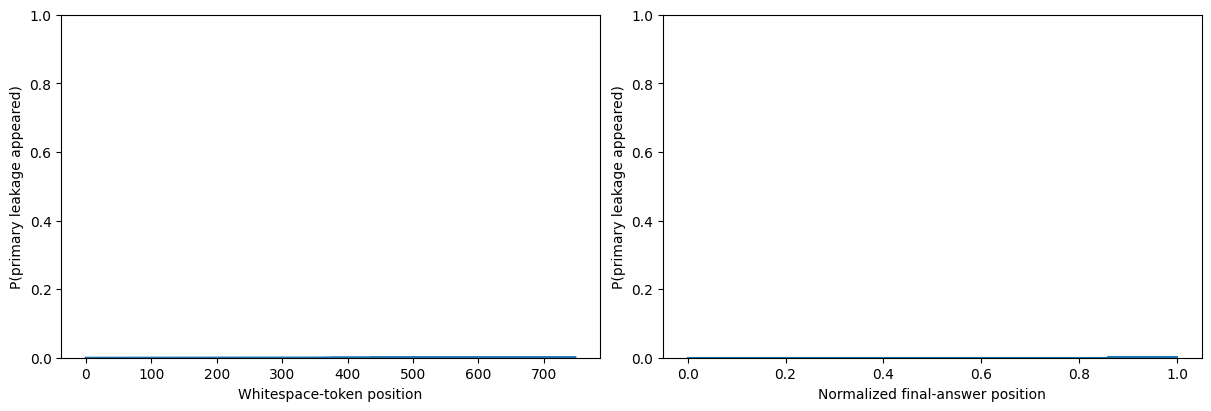

In [21]:
onset = tables['answer_onset']
onset_summary = pd.DataFrame([{
    'answers': len(onset),
    'events': int(onset['onset_event'].sum()),
    'event_rate': onset['onset_event'].mean(),
    'right_censored': int((~onset['onset_event']).sum()),
    'cap_truncated_without_event': int((onset['answer_truncated'] & ~onset['onset_event']).sum()),
    'median_onset_token_if_event': onset.loc[onset['onset_event'], 'first_primary_leak_token'].median(),
    'median_onset_ratio_if_event': onset.loc[onset['onset_event'], 'first_primary_leak_ratio'].median(),
}])
display(onset_summary.style.format({'event_rate': '{:.3%}', 'median_onset_ratio_if_event': '{:.1%}'}))
if PLOTS_AVAILABLE:
    plot_answer_onset(onset)
    plt.show()

## 8. Readiness-landmark analyses not identified by this file

DEER- and EntroCut-centered event studies (plan Analyses IV–V) require per-instance trigger positions. The random-exit continuation rows and prepared trajectory input do not contain those landmarks. This notebook therefore does not manufacture proxies for them. Once a table with columns `data_id`, `deer_position`, and/or `entrocut_position` is supplied, it can be joined to the strict frontier table to compute event-centered leakage and `frontier - trigger` gaps.

## 9. Export reproducible tables

In [22]:
TABLE_DIR.mkdir(parents=True, exist_ok=True)
exports = {**tables, 'stratified_summary': stratified_summary,
           'frontier_summary': frontier_summary, 'sequence_summary': sequence_summary,
           'onset_summary': onset_summary}
for name, table in exports.items():
    table.to_csv(TABLE_DIR / f'{name}.csv', index=False)
print(f'Wrote {len(exports)} tables to {TABLE_DIR}')

Wrote 10 tables to /home/quanghung20gg/Documents/new/early-exit/output/random_exit/analysis/math500.qwen35_4b
